# Heatmap (Transition Matrix)

## Исходные данные для построения

- pivot table с MultiIndex

Как сохранить: `ordered_matrix.to_csv('ordered_matrix.csv')`

In [12]:
aggregated_matrix = pd.read_csv('ordered_matrix.csv', index_col=0)
aggregated_matrix

,New,Active,Loyal,At Risk,Churn
Lifecycle_Stage_from,,,,,
New,4.530744,88.147249,7.322006,0.000000,0.000000
Active,0.000000,61.899162,7.041011,31.059827,0.000000
Loyal,0.000000,6.098790,86.164315,7.736895,0.000000
At Risk,0.000000,7.059585,1.489637,68.037565,23.413212
Churn,0.000000,4.270028,0.040667,0.000000,95.689305


## Код для построения

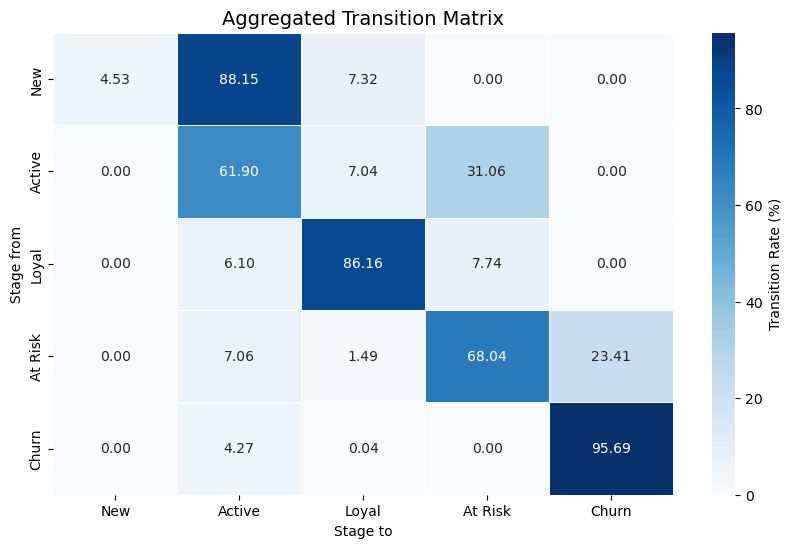

In [13]:
# =====================================================
# IMPORTS
# =====================================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# =====================================================
# LOAD DATA
# =====================================================

# Загрузка с явным указанием индекса
aggregated_matrix = pd.read_csv('ordered_matrix.csv', index_col=0) 

# =====================================================
# PREPARE DATA
# =====================================================

# Явно указать порядок следования стадий
stages = ['New', 'Active', 'Loyal', 'At Risk', 'Churn']

#  Перестроить объект под новый набор меток, поменять порядок строк или столбцов и заполнить пропуски
ordered_matrix = aggregated_matrix.reindex(index=stages, columns=stages, fill_value=0)

# ============================================================
# AGGREGATED TRANSITION MATRIX
# ============================================================
plt.figure(figsize=(10, 6))

heatmap = sns.heatmap(
    ordered_matrix,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    linewidths=.4,
    cbar_kws={'label': 'Transition Rate (%)'} 
)

plt.title('Aggregated Transition Matrix', fontsize=14)
plt.xlabel('Stage to')
plt.ylabel('Stage from')

#plt.savefig("aggregated_transition_matrix.png", dpi=300, bbox_inches="tight")

plt.show()